# Wetland Mapping with TropWet: Spectral Libraries and MESMA

*Section 13 — Case study: wetland mapping (TropWet), notebook 5 of 6.* Previous: `04_finding_endmembers`. Next: `06_endmember_sensitivity`.

TropWet describes every surface with one water, one vegetation and one sand spectrum. Notebook 02 showed that one sand spectrum cannot model both the wet mud and the dry fields, and notebook 04 that endmembers taken from the extremes of the image change the classes completely. This notebook keeps TropWet's idea of endmembers from **known surfaces** (the pixels passing the published NDVI / MNDWI rules), but uses **many spectra per class**:

1. a **spectral library** of 25 spectra per surface, taken from the pure pixels of notebook 01;
2. **library pruning** to the most representative spectra, with the endmember average RMSE (EAR), the minimum average spectral angle (MASA), count-based selection (CoB) and iterative endmember selection (IES);
3. **MESMA** (Roberts et al., 1998): for every pixel, the best of all the models with two or three classes, within fraction and error constraints;
4. **AutoMCU** (Asner & Lobell, 2000): the uncertainty of the fractions due to the variability of the endmembers;
5. a comparison of each result with the **published method** (notebook 02): class areas, per-pixel agreement, fractions and the reference polygons.

**You will learn:**
- how to build, plot and save a spectral library with `make_spectral_library` and `write_spectral_library`;
- how to score and prune a library with `calc_library_ear_masa_cob`, `prune_library` and `select_library_ies`;
- how to run `mesma`, read its model table and choose its constraints;
- how to estimate the fraction uncertainty with `automcu`;
- how to compare a classification with a published one.

**Before you start:** run notebooks 01–03; this notebook reads the composite, the pure pixel masks, the published classification and the reference rasters.

**Data:** `outputs/inputs/`, `outputs/endmembers/`, `outputs/unmixing/` and `outputs/change/`. Outputs are written to `outputs/mesma/`.

**Run time:** ~4 minutes.

## Running Notebook

The notebook has been run and saved with the outputs so you can see what the outputs should be and so the notebook can be browsed online without having to run the notebook for it to make sense.

If you are running the notebook for yourself it is recommended that you clear the existing outputs which can be done by running one of the following options depending on what system you are using:

**Jupyter-lab**:

> \> _Edit_ \> _'Clear All Outputs'_

**Jupyter-notebook**:

> \> _Cell_ \> _'All Outputs'_ \> _Clear_

## 1. Import Modules

In [1]:
# Import the matplotlib plotting module and set it to work within
# a notebook environment.
%matplotlib inline

import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio

import rsgispy
import rsgispy.imagespectral.endmembers as spec_em
import rsgispy.imagespectral.mesma as mesma
from rsgispy.imagecalc.maths import BandDefn, band_maths
from rsgispy.imagecalc.stats import count_pxls_of_val
from rsgispy.imageutils.bands import select_img_bands
from rsgispy.imageutils.colourtable import set_thematic_classes
from rsgispy.imageutils.sampling import extract_img_pxl_vals_in_msk
from rsgispy.mapping.layout import MapPanel, create_map_panels

## 2. Define Input Data and Directories

In [2]:
in_dir = os.path.join("outputs", "inputs")
em_dir = os.path.join("outputs", "endmembers")
unmix_dir = os.path.join("outputs", "unmixing")
chg_dir = os.path.join("outputs", "change")
mesma_dir = os.path.join("outputs", "mesma")
os.makedirs(mesma_dir, exist_ok=True)

refl_scale = 1000.0  # the images are reflectance x 1000
comp_img = os.path.join(in_dir, "sref_composite.tif")
band_names = ["Blue", "Green", "Red", "NIR", "SWIR1", "SWIR2"]
wavelengths = [482, 561, 655, 865, 1609, 2201]
cls_colours = {"Water": "#1F77B4", "Vegetation": "#2CA02C", "Sand": "#D62728"}

# Pure pixel masks of notebook 01: 1 = water, 2 = vegetation, 3 = sand.
tropwet_msk_img = os.path.join(em_dir, "tropwet_pure_pxls.tif")
bright_msk_img = os.path.join(em_dir, "bright_sand_pure_pxls.tif")

## 3. A Spectral Library from the Pure Pixels

A spectral library is a table of spectra (bands as rows) with a **class** for each spectrum: here water, vegetation and sand. The library takes 25 random pure pixels from each of the four sources of notebook 01: the TropWet water, vegetation and sand (wet mud) rules, and the bright sand rule. The sand class therefore holds both wet mud and dry sand spectra. A random generator with a fixed seed makes the selection reproducible.

In [3]:
rng = np.random.default_rng(42)
n_per_source = 25
sources = [
    # (mask image, mask value, class, spectrum name prefix)
    (tropwet_msk_img, 1, "Water", "water"),
    (tropwet_msk_img, 2, "Vegetation", "veg"),
    (tropwet_msk_img, 3, "Sand", "mud"),
    (bright_msk_img, 3, "Sand", "bright"),
]
lib_spectra, lib_classes = {}, []
for msk_img, msk_val, cls_name, prefix in sources:
    pxls = extract_img_pxl_vals_in_msk(
        comp_img, list(range(1, 7)), msk_img, msk_val, no_data_val=0, use_pbar=False
    )
    sel = rng.choice(len(pxls), size=min(n_per_source, len(pxls)), replace=False)
    for k, idx in enumerate(sel):
        lib_spectra[f"{prefix}_{k}"] = pxls[idx]
        lib_classes.append(cls_name)

library = spec_em.make_spectral_library(
    pd.DataFrame(lib_spectra, index=pd.Index(band_names, name="band")), lib_classes
)
spec_em.write_spectral_library(library, os.path.join(mesma_dir, "spectral_library.csv"))
print(f"{library.shape[1]} spectra:", spec_em.library_classes(library).value_counts().to_dict())
library.iloc[:, ::25].round(0)  # one spectrum from each source

100 spectra: {'Sand': 50, 'Water': 25, 'Vegetation': 25}


class      Water Vegetation   Sand         
spectrum water_0      veg_0  mud_0 bright_0
band                                       
Blue        59.0       29.0   55.0     88.0
Green       94.0       54.0   79.0    134.0
Red         76.0       43.0   94.0    167.0
NIR         36.0      310.0  130.0    235.0
SWIR1       20.0      172.0   74.0    315.0
SWIR2       14.0       78.0   46.0    252.0

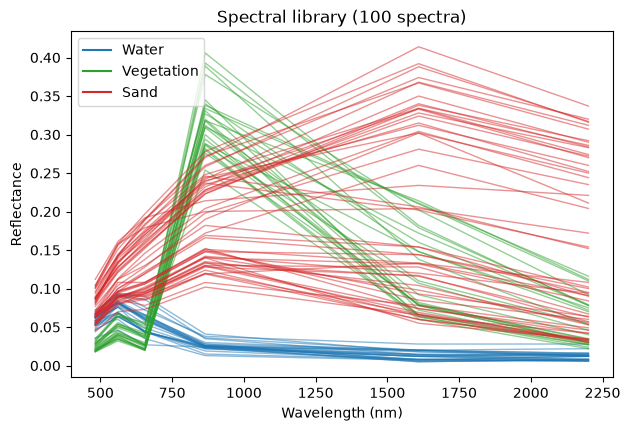

In [4]:
def plot_library(lib, title, ax):
    """Plot every spectrum of a library, coloured by class."""
    classes = spec_em.library_classes(lib)
    for spec_name, cls_name in classes.items():
        ax.plot(wavelengths, lib.xs(spec_name, axis=1, level="spectrum").iloc[:, 0] / refl_scale,
                color=cls_colours[cls_name], alpha=0.5, lw=1)
    for cls_name, colour in cls_colours.items():
        ax.plot([], [], color=colour, label=cls_name)
    ax.set_xlabel("Wavelength (nm)")
    ax.set_ylabel("Reflectance")
    ax.set_title(title)
    ax.legend()


fig, ax = plt.subplots(figsize=(7, 4.5))
plot_library(library, "Spectral library (100 spectra)", ax)
plt.show()

The water spectra are similar to each other, the vegetation spectra vary in brightness, and the sand class is two groups: the dark wet mud and the much brighter dry sand. This is the variability that one endmember per class cannot represent.

## 4. Pruning the Library

MESMA fits every combination of spectra, so the run time grows quickly with the library size (with 25 spectra per class, a three-class model alone has 25 x 25 x 50 = 31,250 combinations). Pruning keeps the spectra that best represent their class.

### 4.1 EAR, MASA and CoB

`calc_library_ear_masa_cob` models every spectrum with every other spectrum (one spectrum plus a zero shade) and gives, for each spectrum:

- **EAR** (endmember average RMSE; Dennison & Roberts, 2003): the mean RMSE when it models the other spectra of its class (low = representative);
- **MASA** (minimum average spectral angle; Dennison et al., 2004): the mean spectral angle to the other spectra of its class;
- **in-CoB / out-CoB** (count-based selection; Roberts et al., 2003): how many spectra of its own / of other classes it models within the fraction and RMSE limits (high in-CoB and low out-CoB = representative and specific).

`gain` puts the spectra in reflectance (0–1), the units of the RMSE limit (0.025).

In [5]:
scores = mesma.calc_library_ear_masa_cob(library, gain=refl_scale)
scores.groupby("class")[["ear", "masa", "in_cob", "out_cob", "out_ear"]].mean().round(3)

,ear,masa,in_cob,out_cob,out_ear
class,,,,,
Sand,0.040,0.268,13.90,3.34,0.060
Vegetation,0.025,0.169,8.60,1.00,0.080
Water,0.006,0.138,14.28,0.00,0.119


The class means summarise the variability seen in the plot:

- **Water** is the most consistent class: its spectra model each other with a mean RMSE (EAR) of 0.006 and a mean angle (MASA) of 0.14 rad, and no water spectrum models a spectrum of another class (out-CoB 0).
- **Vegetation** varies mainly in brightness (EAR 0.025, which is at the RMSE limit): the bright and the shaded canopies.
- **Sand** is the least consistent (EAR 0.040, MASA 0.27) and the least specific (out-CoB 3.3: a sand spectrum, with a shade, also models several water or vegetation spectra), because it holds two different surfaces.

`prune_library` keeps the `n_per_class` best spectra of each class by one of the scores:

In [6]:
pruned = {
    method: mesma.prune_library(library, method=method, n_per_class=4, gain=refl_scale)
    for method in ("ear", "masa", "cob")
}
pd.DataFrame(
    {method: list(lib.columns.get_level_values("spectrum")) for method, lib in pruned.items()}
)

,ear,masa,cob
0,water_3,water_3,water_0
1,water_5,water_5,water_8
2,water_7,water_15,water_13
3,water_21,water_21,water_24
4,veg_12,veg_13,veg_14
5,veg_17,veg_17,veg_15
6,veg_18,veg_23,veg_17
7,veg_24,veg_24,veg_18
8,bright_0,mud_8,mud_4
9,bright_6,mud_18,mud_5


### 4.2 Iterative endmember selection (IES)

IES (Schaaf et al., 2011) builds the library the other way round: it starts empty and repeatedly adds the spectrum that most improves the classification of the library spectra themselves (each spectrum is assigned the class of the spectrum that models it best; the score is Cohen's kappa), removing spectra that no longer help.

In [7]:
ies_lib, ies_hist = mesma.select_library_ies(library, gain=refl_scale)
print(f"IES kept {ies_lib.shape[1]} spectra:",
      spec_em.library_classes(ies_lib).value_counts().to_dict())
ies_hist.round(3)

IES kept 10 spectra: {'Sand': 5, 'Vegetation': 3, 'Water': 2}


,iteration,action,spectrum,score
0,1,add,water_8,0.191
1,2,add,mud_5,0.374
2,3,add,bright_14,0.566
3,4,add,veg_18,0.778
4,5,add,veg_2,0.878
5,6,add,veg_14,0.908
6,7,add,mud_1,0.938
7,8,add,water_13,0.953
8,9,add,mud_11,0.969
9,10,add,bright_6,0.984


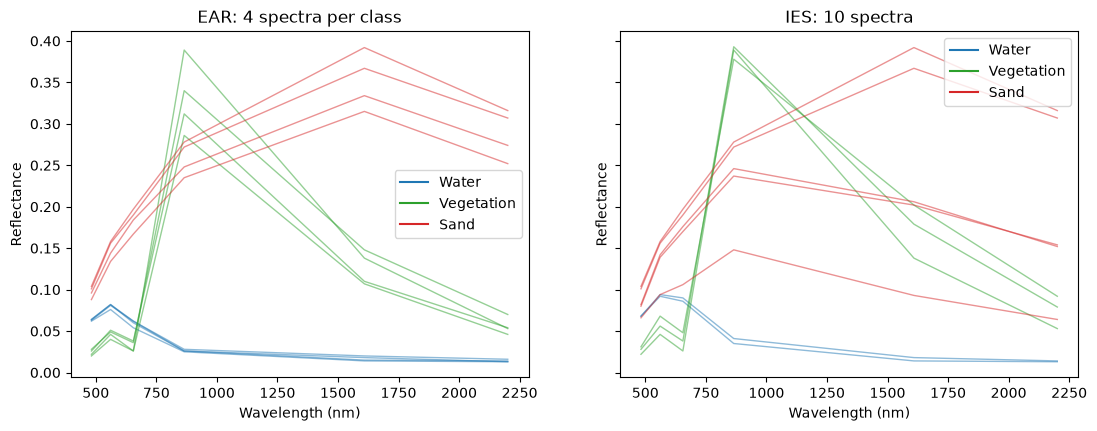

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
plot_library(pruned["ear"], "EAR: 4 spectra per class", axs[0])
plot_library(ies_lib, f"IES: {ies_lib.shape[1]} spectra", axs[1])
plt.show()

The three scores keep **different sand spectra**, and this decides what the library can model:

- **EAR** keeps only bright sand (`bright_*`). With a zero shade, a bright spectrum can be scaled down to model a darker one, but a dark spectrum cannot be scaled up beyond a fraction of ~1, so the brightest spectra have the lowest mean RMSE.
- **MASA** and **CoB** keep only wet mud (`mud_*`). The spectral angle ignores brightness, and the mud spectra are the tighter of the two groups within the class.
- **IES** keeps both: kappa rises from 0.19 (one water spectrum) to 0.98 with 10 spectra, and the second and third spectra added are a mud and a bright sand spectrum, because the library spectra cannot be classified correctly without both.

A pruned library is therefore not only a smaller library: the score chooses which surfaces of a class are represented. The EAR library is used below, as it is the most common choice for MESMA; the IES library is compared with it in section 6.

## 5. MESMA

`mesma` unmixes every pixel with every model of the library at the requested **levels** (the number of classes in a model): here every pair of classes (water–vegetation, water–sand, vegetation–sand) and all three classes, each with one spectrum per class. The fractions of a model are solved with FCLS. A model passes when:

- its fractions are within −0.05 and 1.05 (`min_frac`, `max_frac`);
- its RMSE is at most 0.025 reflectance (`max_rmse`);
- its residual is not above 0.025 in 7 consecutive bands (`max_resid`, `n_consec_bands`; with six Landsat bands this rarely matters).

The passing model with the lowest RMSE is kept, but a three-class model must lower the RMSE by more than `min_rmse_gain` (0.002) to replace a two-class model: adding a class always lowers the error a little, even when the third class is not there. Pixels where no model passes are written as no data. The EAR-pruned library (4 spectra per class) is used.

In [9]:
mesma_img = os.path.join(mesma_dir, "composite_mesma_ear.tif")
models = mesma.mesma(
    comp_img,
    mesma_img,
    pruned["ear"],
    levels=(2, 3),
    min_rmse_gain=0.002,
    gain=refl_scale,
    out_models_file=os.path.join(mesma_dir, "mesma_ear_models.csv"),
    use_pbar=False,
)
print(f"{len(models)} models ({(models['level'] == 2).sum()} with two classes, "
      f"{(models['level'] == 3).sum()} with three)")
models.head()

112 models (48 with two classes, 64 with three)


,model,level,classes,spectra
0,1,2,Water+Vegetation,water_3+veg_12
1,2,2,Water+Vegetation,water_3+veg_17
2,3,2,Water+Vegetation,water_3+veg_18
3,4,2,Water+Vegetation,water_3+veg_24
4,5,2,Water+Vegetation,water_5+veg_12


In [10]:
with rasterio.open(mesma_img) as src:
    print("Output bands:", src.descriptions)
    model_arr = src.read(4)
    mesma_nd = src.nodata
with rasterio.open(comp_img) as src:
    comp_vld = np.all(src.read() > 0, axis=0)
modelled = (model_arr != mesma_nd) & comp_vld
print(f"Pixels with a model within the constraints: {100 * modelled.sum() / comp_vld.sum():.1f} %")

# The number of classes in the chosen model (the models are ordered by level).
n_level2 = int((models["level"] == 2).sum())
level_img = os.path.join(mesma_dir, "composite_mesma_ear_level.tif")
band_maths(
    level_img, f"model == -9999 ? 0 : (model <= {n_level2} ? 2 : 3)",
    [BandDefn("model", mesma_img, 4)], datatype=rsgispy.TYPE_8UINT, no_data_val=0,
    use_pbar=False,
)
set_thematic_classes(level_img, {2: ("Two classes", "#9ECAE1"), 3: ("Three classes", "#08519C")})
chosen = models.set_index("model").loc[model_arr[modelled].astype(int), "classes"]
(100 * chosen.value_counts(normalize=True)).round(1).rename("% of modelled pixels")

Output bands: ('Water', 'Vegetation', 'Sand', 'model', 'RMSE')
Pixels with a model within the constraints: 97.4 %


classes
Water+Vegetation         50.8
Vegetation+Sand          29.4
Water+Vegetation+Sand    12.7
Water+Sand                7.2
Name: % of modelled pixels, dtype: float64

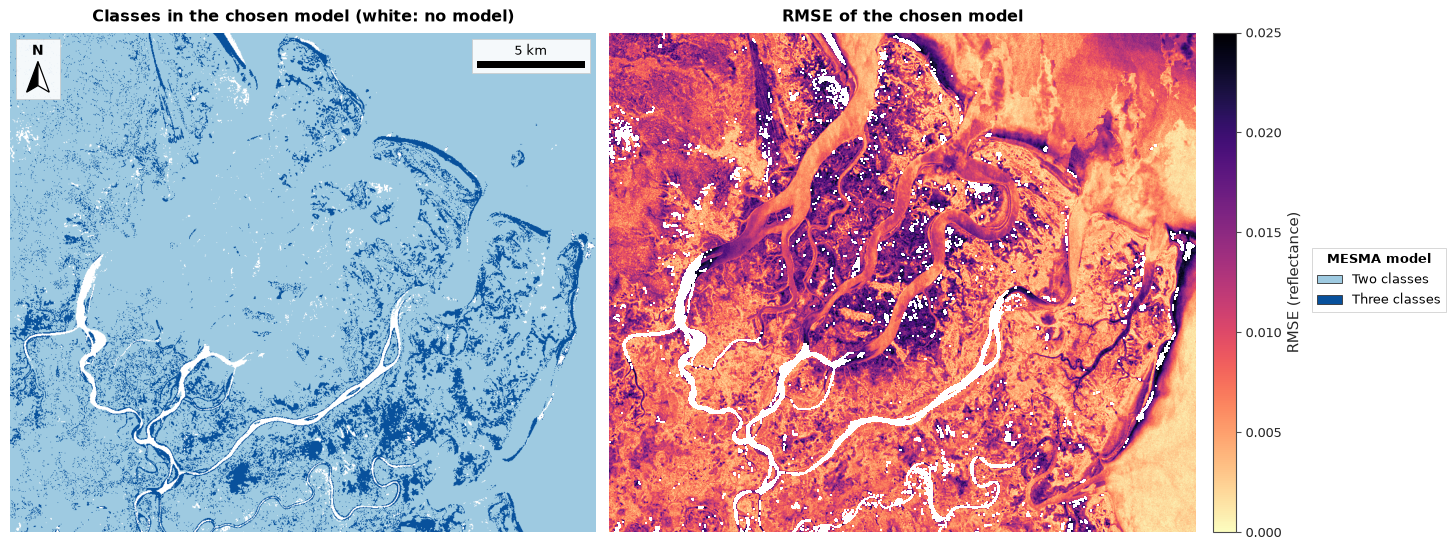

In [11]:
fig, axs = create_map_panels(
    [
        MapPanel("thematic", level_img, title="Classes in the chosen model (white: no model)"),
        MapPanel("cmap", mesma_img, bands=5, title="RMSE of the chosen model",
                 cmap_name="magma_r", vmin=0, vmax=0.025, show_colour_bar=True,
                 cbar_label="RMSE (reflectance)"),
    ],
    figsize=(13, 5.5),
    legend_title="MESMA model",
)

97.4 % of the pixels have a model within the constraints. Half of them are modelled with water and vegetation (the mangroves and the creeks), 29 % with vegetation and sand (the fields and the dry land), 7 % with water and sand (the turbid water and the coast) and 13 % need all three classes, mainly the fields in the south and the edges of the mangrove blocks.

The pixels with **no model** (white) are almost all in the large river channels: turbid, sediment-laden water that is brighter than every water spectrum in the library and that no combination models within the 0.025 RMSE limit. The RMSE map shows the same pattern at a lower level: it is lowest at sea and on the dry land, and highest (0.015–0.025) in the creeks and the inner mangroves, where water, vegetation and mud are mixed within a pixel.

### 5.1 Without the constraints

To see what the constraints do, the same library is run without them (every pixel gets its lowest-RMSE model).

In [12]:
mesma_nc_img = os.path.join(mesma_dir, "composite_mesma_ear_noconstraints.tif")
mesma.mesma(
    comp_img, mesma_nc_img, pruned["ear"], levels=(2, 3), min_rmse_gain=0.002,
    gain=refl_scale, min_frac=None, max_frac=None, max_rmse=None, max_resid=None,
    use_pbar=False,
)
with rasterio.open(mesma_nc_img) as src:
    rmse_nc = src.read(5)
print(f"RMSE of the pixels the constraints rejected: median "
      f"{np.median(rmse_nc[comp_vld & ~modelled]):.3f}, of the others "
      f"{np.median(rmse_nc[modelled]):.3f} (reflectance)")

RMSE of the pixels the constraints rejected: median 0.029, of the others 0.008 (reflectance)


## 6. Classes and Comparison with the Published Method

The MESMA fractions (bands 1–3) are classified with the TropWet rules, as in notebook 02. Four results are compared with the published method (the TropWet endmembers): the two-model MESMA of notebook 02 and the library MESMA with and without constraints, and also the IES library.

In [13]:
TROPWET_CLASSES = {
    1: ("Open Water (OW)", "#08519C"),
    2: ("Emergent Flooded Vegetation (EFV)", "#3FB8AF"),
    3: ("Wet Bare Sand (WBS)", "#B39C4D"),
    4: ("Dense Vegetation (GV)", "#1B7837"),
    5: ("Dry Sparse Vegetation (DSV)", "#A6D96A"),
    6: ("Dry Bare Sand (DBS)", "#F4E2B8"),
    7: ("Mixed / Other", "#BDBDBD"),
}
cls_names = {val: name for val, (name, _) in TROPWET_CLASSES.items()}
cls_abbrv = {val: name.split("(")[-1].rstrip(")") if "(" in name else "Other"
             for val, name in cls_names.items()}


def fracs_to_pct(frac_img, pct_img):
    """FCLS fractions (no data -9999) to percentages (no data -999)."""
    band_maths(
        pct_img,
        ", ".join(f"{name} == -9999 ? -999 : 100 * {name}" for name in "WVS"),
        [BandDefn(name, frac_img, idx) for idx, name in enumerate("WVS", start=1)],
        band_names=["Water", "Vegetation", "Sand"],
        no_data_val=-999,
        use_pbar=False,
    )
    return pct_img


def classify_tropwet(pct_img, cls_img, hi=75, lo=25):
    """TropWet class rules (Hardy et al., 2020, Table 3) on W, V, S in %."""
    rules = [
        (1, f"W >= {hi}"),
        (2, f"W + V >= {hi} && V >= {lo} && V < {hi} && W >= {lo} && W < {hi}"),
        (3, f"W + S >= {hi} && W >= {lo} && W < {hi} && S >= {lo} && S < {hi}"),
        (4, f"V >= {hi}"),
        (5, f"V + S >= {hi} && V >= {lo} && V < {hi} && S >= {lo} && S < {hi}"),
        (6, f"S >= {hi}"),
    ]
    exp = "W < 0 ? 0 : "  # no data
    for code, rule in rules:
        exp += f"(({rule}) ? {code} : "
    exp += "7" + ")" * len(rules)  # anything else: Mixed / Other
    band_maths(
        cls_img,
        exp,
        [BandDefn(name, pct_img, idx) for idx, name in enumerate("WVS", start=1)],
        datatype=rsgispy.TYPE_8UINT,
        band_names=["tropwet_class"],
        no_data_val=0,
        use_pbar=False,
    )
    set_thematic_classes(cls_img, TROPWET_CLASSES)
    return cls_img


def class_areas_ha(cls_img):
    """Area (ha) of each TropWet class."""
    with rasterio.open(cls_img) as src:
        pxl_ha = abs(src.res[0] * src.res[1]) / 10000.0
    counts = count_pxls_of_val(cls_img, list(TROPWET_CLASSES), img_band=1, use_pbar=False)
    return pd.Series(counts * pxl_ha, index=pd.Index(cls_abbrv.values(), name="class"))

In [14]:
mesma_ies_img = os.path.join(mesma_dir, "composite_mesma_ies.tif")
mesma.mesma(comp_img, mesma_ies_img, ies_lib, levels=(2, 3), min_rmse_gain=0.002,
            gain=refl_scale, use_pbar=False)

runs = {
    "MESMA EAR": mesma_img,
    "MESMA EAR, no constraints": mesma_nc_img,
    "MESMA IES": mesma_ies_img,
}
frac_imgs = {
    "published": os.path.join(unmix_dir, "composite_tropwet_fcls.tif"),
    "two-model MESMA (nb 02)": os.path.join(unmix_dir, "composite_mesma_fcls.tif"),
}
cls_imgs = {
    "published": os.path.join(unmix_dir, "composite_tropwet_classes.tif"),
    "two-model MESMA (nb 02)": os.path.join(unmix_dir, "composite_mesma_classes.tif"),
}
for name, out_img in runs.items():
    tag = name.lower().replace(" ", "_").replace(",", "")
    frac_imgs[name] = os.path.join(mesma_dir, f"{tag}_fcls.tif")
    select_img_bands(out_img, frac_imgs[name], [1, 2, 3], calc_stats=False, use_pbar=False)
    pct_img = fracs_to_pct(frac_imgs[name], os.path.join(mesma_dir, f"{tag}_pct.tif"))
    cls_imgs[name] = classify_tropwet(pct_img, os.path.join(mesma_dir, f"{tag}_classes.tif"))

In [15]:
def read_band(img, band=1):
    with rasterio.open(img) as src:
        return src.read(band)


# The published method (notebook 02): TropWet endmembers, FCLS, TropWet rules.
published_cls_img = os.path.join(unmix_dir, "composite_tropwet_classes.tif")
published_cls = read_band(published_cls_img)


def agreement_with_published(cls_img):
    """Share (%) of the pixels with the same class as the published method."""
    cls_arr = read_band(cls_img)
    vld = (cls_arr > 0) & (published_cls > 0)
    return 100 * np.mean(cls_arr[vld] == published_cls[vld])


def from_to_published(cls_img):
    """Area (ha) of each published class (rows) in each class of cls_img (columns)."""
    cls_arr = read_band(cls_img)
    vld = (cls_arr > 0) & (published_cls > 0)
    order = list(cls_abbrv.values())
    tab = pd.crosstab(
        pd.Series(published_cls[vld], name="published").map(cls_abbrv),
        pd.Series(cls_arr[vld], name="this set").map(cls_abbrv),
    ) * 0.09
    return tab.reindex(index=order, columns=order, fill_value=0)


# Reference polygons of notebook 03 (water, mangroves, other terrestrial),
# rasterised on the 1997 and 2018 images; both are on the composite's grid.
ref_97 = read_band(os.path.join(chg_dir, "reference_1997.tif"))
ref_18 = read_band(os.path.join(chg_dir, "reference_2018.tif"))
ref_arr = np.where(ref_97 > 0, ref_97, ref_18)
ref_arr[(ref_97 > 0) & (ref_18 > 0) & (ref_97 != ref_18)] = 0  # disagreeing labels


def reference_check(cls_img):
    """% of the water reference mapped as Open Water, of the mangroves as
    vegetated (GV or EFV) and of the other land as a dry class (GV, DSV, DBS)."""
    cls_arr = read_band(cls_img)
    vld = (ref_arr > 0) & (cls_arr > 0)
    ref, cls_v = ref_arr[vld], cls_arr[vld]
    return pd.Series({
        "water -> OW (%)": 100 * np.mean(cls_v[ref == 1] == 1),
        "mangroves -> GV or EFV (%)": 100 * np.mean(np.isin(cls_v[ref == 2], [2, 4])),
        "other land -> GV, DSV or DBS (%)": 100 * np.mean(np.isin(cls_v[ref == 3], [4, 5, 6])),
    })

In [16]:
area_df = pd.DataFrame({name: class_areas_ha(cls_img) for name, cls_img in cls_imgs.items()})
area_df.loc["no model"] = [0.09 * np.sum((read_band(img) == 0) & comp_vld)
                           for img in cls_imgs.values()]
area_df.loc["agreement (%)"] = [agreement_with_published(img) for img in cls_imgs.values()]
area_df.round(0)

,published,two-model MESMA (nb 02),MESMA EAR,"MESMA EAR, no constraints",MESMA IES
class,,,,,
OW,15611.0,15682.0,15612.0,16718.0,15496.0
EFV,2609.0,3109.0,3987.0,4040.0,14515.0
WBS,1399.0,1479.0,183.0,194.0,604.0
GV,33341.0,28386.0,29716.0,30011.0,20731.0
DSV,8113.0,9220.0,8126.0,8166.0,2772.0
DBS,475.0,1303.0,1040.0,1136.0,686.0
Other,581.0,2948.0,1855.0,1862.0,5037.0
no model,0.0,0.0,1607.0,0.0,2286.0
agreement (%),100.0,85.0,83.0,82.0,66.0


In [17]:
def fraction_differences(frac_img):
    """Mean absolute difference (percentage points) from the published fractions."""
    with rasterio.open(frac_img) as src:
        fracs = src.read()
    with rasterio.open(frac_imgs["published"]) as src:
        pub = src.read()
    vld = (fracs[0] != -9999) & (pub[0] != -9999)
    return pd.Series(
        100 * np.mean(np.abs(fracs[:, vld] - pub[:, vld]), axis=1),
        index=["Water", "Vegetation", "Sand"],
    )


pd.DataFrame({name: fraction_differences(img) for name, img in frac_imgs.items()}).round(1)

,published,two-model MESMA (nb 02),MESMA EAR,"MESMA EAR, no constraints",MESMA IES
Water,0.0,2.1,6.3,6.5,12.7
Vegetation,0.0,5.4,8.8,8.8,10.1
Sand,0.0,6.5,6.8,7.1,7.3


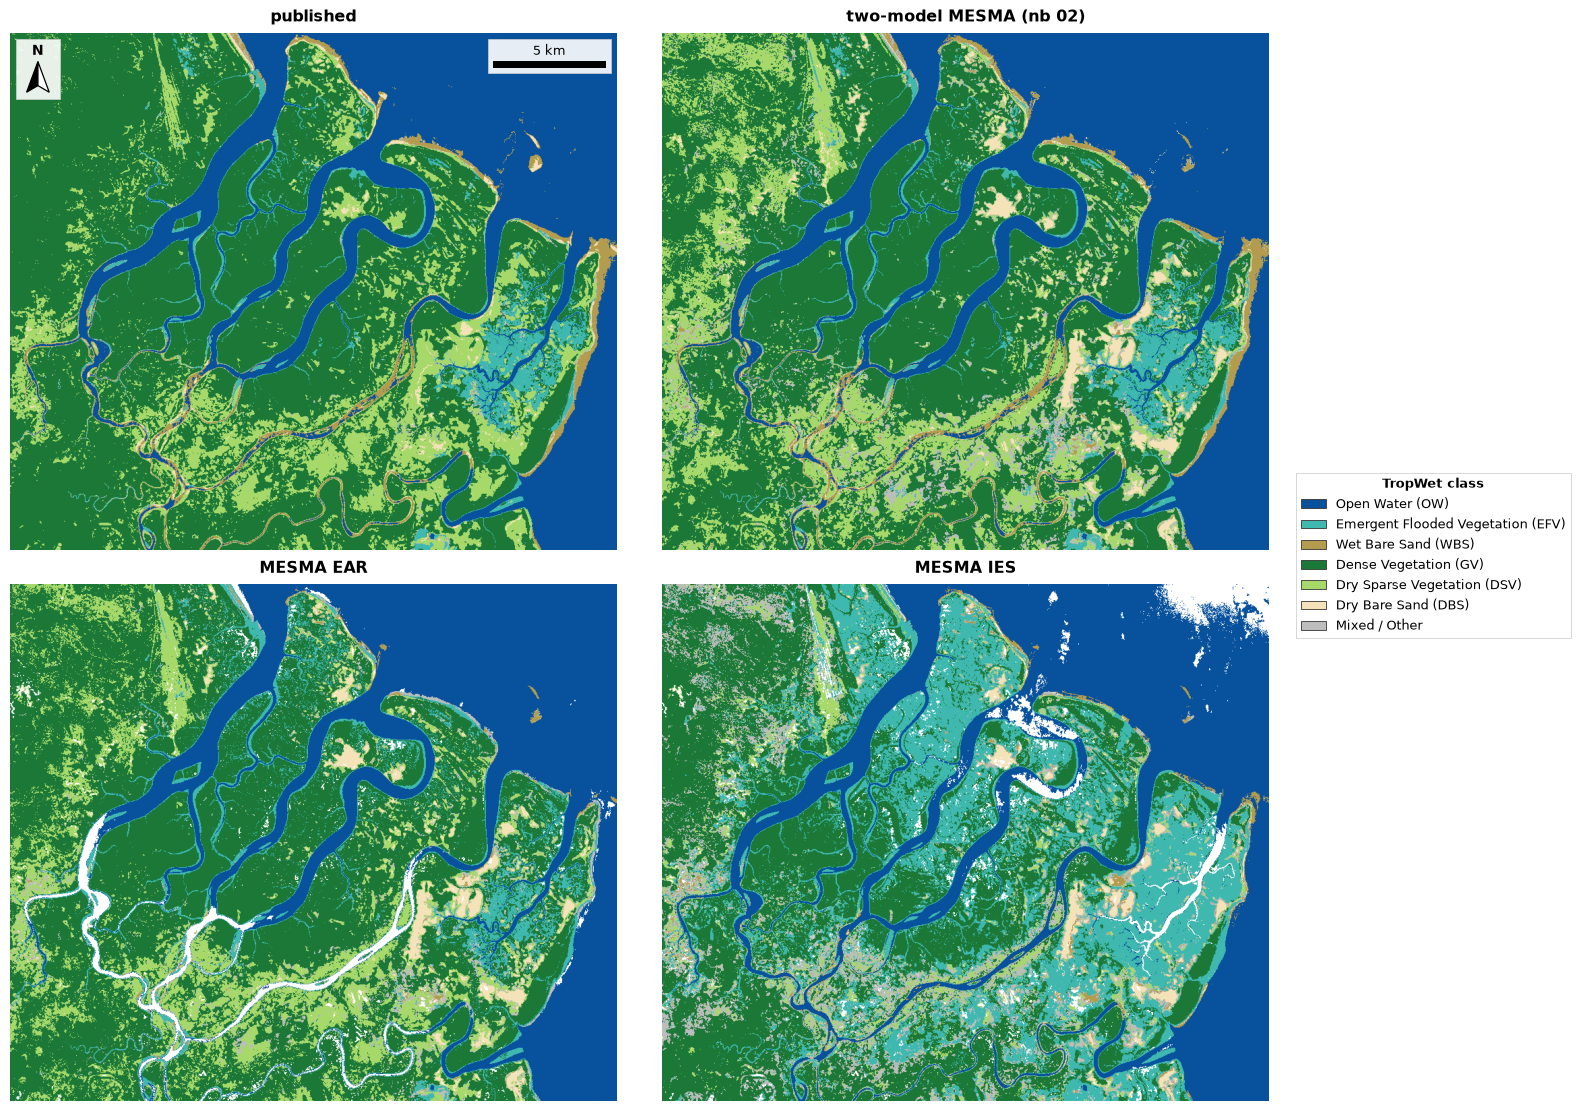

In [18]:
fig, axs = create_map_panels(
    [MapPanel("thematic", cls_imgs[name], title=name)
     for name in ("published", "two-model MESMA (nb 02)", "MESMA EAR", "MESMA IES")],
    ncols=2,
    figsize=(13, 11),
    legend_title="TropWet class",
)

In [19]:
from_to_published(cls_imgs["MESMA EAR"]).round(0)

this set,OW,EFV,WBS,GV,DSV,DBS,Other
published,,,,,,,
OW,14944.0,44.0,0.0,0.0,0.0,0.0,0.0
EFV,9.0,1793.0,0.0,772.0,0.0,0.0,35.0
WBS,621.0,94.0,6.0,0.0,0.0,0.0,176.0
GV,0.0,1250.0,0.0,28276.0,3194.0,5.0,241.0
DSV,0.0,500.0,5.0,505.0,4933.0,944.0,1148.0
DBS,1.0,44.0,171.0,0.0,0.0,91.0,148.0
Other,36.0,261.0,0.0,164.0,0.0,0.0,108.0


In [20]:
pd.DataFrame({name: reference_check(img) for name, img in cls_imgs.items()}).round(1)

,published,two-model MESMA (nb 02),MESMA EAR,"MESMA EAR, no constraints",MESMA IES
water -> OW (%),97.4,97.4,98.1,98.2,98.2
mangroves -> GV or EFV (%),98.7,98.4,99.5,99.5,98.5
"other land -> GV, DSV or DBS (%)",99.6,89.6,96.5,96.6,63.4


**How different are the results from the published method?**

- **Overall**: 83 % of the pixels have the same class with the EAR library, 85 % with the two-model MESMA of notebook 02 and only 66 % with the IES library (pixels without a model are excluded). The mean absolute difference of the fractions is 6–9 percentage points for the EAR library and 2–7 points for the two-model MESMA.
- **Open water** has the same area (15,612 against 15,611 ha), but not the same pixels: 621 ha of the published WBS become OW, while the turbid river channels, OW in the published map, have no model. Without the constraints they are classified as OW and the area rises to 16,718 ha, so the constraints change the area, not the classification of the modelled pixels (82 % agreement).
- **Wet bare sand almost disappears** (1,399 → 183 ha): the EAR library has no wet mud spectrum, so the mud flats are modelled as water plus bright sand with a low sand fraction. The two-model MESMA of notebook 02, which has a mud spectrum, keeps it (1,479 ha).
- **EFV increases** by 1,378 ha and **GV decreases** by 3,625 ha: 1,250 ha of the published GV becomes EFV and 3,194 ha becomes DSV. EAR also favours the brighter vegetation spectra (as for the sand), so a darker canopy pixel is more often modelled as bright vegetation plus some water (EFV) or sand (DSV).
- **Against the reference polygons** the EAR library is as good as the published endmembers for water (98.1 %, against 97.4 %) and mangroves (99.5 %, against 98.7 %) and slightly worse for the other land (96.5 %, against 99.6 %).
- **The IES library** differs much more: EFV 14,515 ha against 2,609 ha and only 63 % of the other land mapped as a dry class. Its library is the best at classifying the library spectra themselves, but in the image large areas of the published GV and DSV are given a water fraction above 0.25 and become EFV.

The differences are therefore concentrated in the mixed classes (EFV, WBS, DSV), and they depend more on **which spectra are in the library** (the pruning method) than on using MESMA instead of FCLS.

## 7. Uncertainty from the Endmember Variability (AutoMCU)

MESMA picks one model per pixel; it does not say how much the fractions would change with another, equally plausible, spectrum. AutoMCU answers that: every pixel is unmixed `n_iter` times, each time with one spectrum drawn at random from each class (all three classes, FCLS), and the mean and standard deviation of the fractions are written. The draws depend only on the pixel and the seed, so the result is reproducible.

The run time grows with the number of different spectrum combinations drawn (each is solved separately), so a library pruned to 8 spectra per class by EAR is used (8 x 8 x 8 = 512 combinations); with the full library (up to 25 x 25 x 50 = 31,250 combinations) AutoMCU takes many times longer.

In [21]:
mcu_lib = mesma.prune_library(library, method="ear", n_per_class=8, gain=refl_scale)
mcu_img = os.path.join(mesma_dir, "composite_automcu.tif")
mesma.automcu(comp_img, mcu_img, mcu_lib, n_iter=30, rnd_seed=42, gain=refl_scale,
              use_pbar=False)
with rasterio.open(mcu_img) as src:
    print("Output bands:", src.descriptions)
    mcu = src.read()
mcu_vld = mcu[0] != -9999
pd.DataFrame(
    {
        "mean fraction": mcu[0:3, mcu_vld].mean(axis=1),
        "median sd": np.median(mcu[3:6, mcu_vld], axis=1),
        "p95 sd": np.percentile(mcu[3:6, mcu_vld], 95, axis=1),
    },
    index=["Water", "Vegetation", "Sand"],
).round(3)

Output bands: ('Water_mean', 'Vegetation_mean', 'Sand_mean', 'Water_std', 'Vegetation_std', 'Sand_std', 'RMSE')


,mean fraction,median sd,p95 sd
Water,0.359,0.066,0.131
Vegetation,0.520,0.053,0.129
Sand,0.121,0.023,0.071


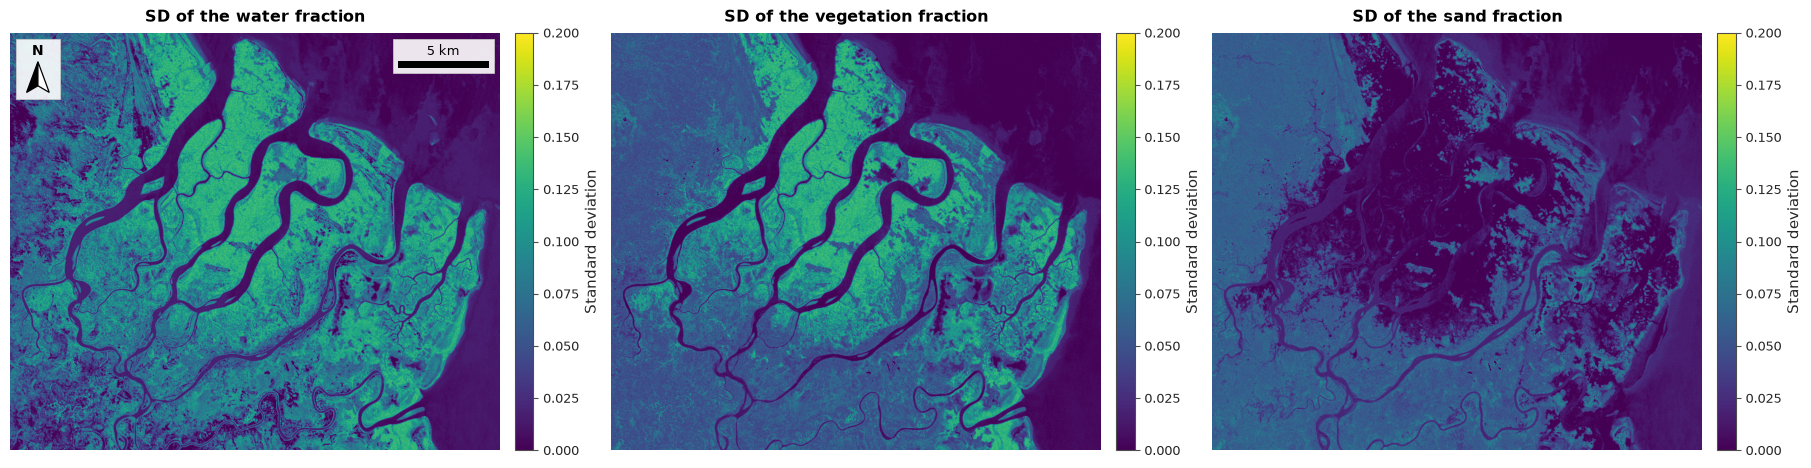

In [22]:
fig, axs = create_map_panels(
    [
        MapPanel("cmap", mcu_img, bands=4 + idx, title=f"SD of the {name.lower()} fraction",
                 cmap_name="viridis", vmin=0, vmax=0.2, show_colour_bar=True,
                 cbar_label="Standard deviation")
        for idx, name in enumerate(["Water", "Vegetation", "Sand"])
    ],
    figsize=(18, 5),
)

The standard deviation of the fractions is the uncertainty due to the endmember variability alone (the pure pixels are all valid examples of their class). It is small at sea and on the dry land, where one class dominates, and largest in the mangroves and the creeks: the median is 0.07 for water and 0.05 for vegetation, and 5 % of the pixels have a water or vegetation SD above 0.13. The sand fraction is the most stable (median 0.02), because most pixels have little sand.

The TropWet classes are bands of fractions 0.25 or 0.50 wide (e.g. EFV: water and vegetation between 0.25 and 0.75). A pixel near a class boundary with an SD of 0.1 can therefore fall on either side of it depending on the spectra chosen, which is why the mixed classes differ most between the libraries in section 6. Notebook 06 measures the same effect for the published method.

## 8. Summary

- A spectral library with many spectra per class represents the variability within each surface that one endmember cannot; for the Saloum delta, the main variability is the two surfaces (wet mud and dry sand) of the sand class and the brightness of the vegetation.
- **The pruning method decides what is represented**: EAR keeps the brightest sand spectra, MASA and CoB the wet mud, and IES both. Look at the spectra a pruning keeps before using them.
- MESMA with the EAR library agrees with the published method for 83 % of the pixels. Open water and the dense vegetation are similar; the mixed classes differ, and wet bare sand almost disappears because the library has no mud spectrum.
- The MESMA constraints reject the pixels that no model fits (here the turbid river water); without them these pixels are still classified, but with a high RMSE.
- AutoMCU shows that the variability of the endmembers alone moves the fractions by 0.05–0.13 in the mixed areas, comparable to the width of the TropWet class bands.

Next, notebook `06_endmember_sensitivity` measures how sensitive the published method itself is to the endmember selection: which pixels are picked, and the NDVI / MNDWI rules that pick them.

**References**
- Asner, G. P., Lobell, D. B. (2000). A biogeophysical approach for automated SWIR unmixing of soils and vegetation. *Remote Sensing of Environment*, 74(1), 99–112.
- Dennison, P. E., Roberts, D. A. (2003). Endmember selection for multiple endmember spectral mixture analysis using endmember average RMSE. *Remote Sensing of Environment*, 87(2–3), 123–135.
- Dennison, P. E., Halligan, K. Q., Roberts, D. A. (2004). A comparison of error metrics and constraints for multiple endmember spectral mixture analysis and spectral angle mapper. *Remote Sensing of Environment*, 93(3), 359–367.
- Hardy, A., Oakes, G., Ettritch, G. (2020). Tropical Wetland (TropWet) Mapping Tool: The Automatic Detection of Open and Vegetated Waterbodies in Google Earth Engine for Tropical Wetlands. *Remote Sensing*, 12(7), 1182. https://doi.org/10.3390/rs12071182
- Roberts, D. A., Gardner, M., Church, R., Ustin, S., Scheer, G., Green, R. O. (1998). Mapping chaparral in the Santa Monica Mountains using multiple endmember spectral mixture models. *Remote Sensing of Environment*, 65(3), 267–279.
- Roberts, D. A., Dennison, P. E., Gardner, M. E., Hetzel, Y., Ustin, S. L., Lee, C. T. (2003). Evaluation of the potential of Hyperion for fire danger assessment by comparison to the Airborne Visible/Infrared Imaging Spectrometer. *IEEE Transactions on Geoscience and Remote Sensing*, 41(6), 1297–1310.
- Schaaf, A. N., Dennison, P. E., Fryer, G. K., Roth, K. L., Roberts, D. A. (2011). Mapping plant functional types at multiple spatial resolutions using imaging spectrometer data. *GIScience & Remote Sensing*, 48(3), 324–344.

Landsat data courtesy of the U.S. Geological Survey.